In [2]:
!pip install Sastrawi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 7.1 MB/s eta 0:00:00


In [3]:
import numpy as np
import pandas as pd
import re
import nltk
from functools import lru_cache
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from google.colab import drive
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from collections import Counter
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import joblib
from sklearn.metrics import silhouette_score
import pickle

In [4]:
# Load Data
drive.mount('/content/drive')

data = pd.read_csv('/content/drive/MyDrive/Clustering Teks Twitter/mbg.csv')

data.head()

Mounted at /content/drive


,conversation_id_str,created_at,favorite_count,full_text,id_str,image_url,in_reply_to_screen_name,lang,location,quote_count,reply_count,retweet_count,tweet_url,user_id_str,username
0,2104853720001659234,2026-09-29T08:40:07.000Z,33,Belasan Siswa SMPN 1 Tabulahan Diduga Keracuna...,2104853720001659234,https://pbs.twimg.com/amplify_video_thumb/2104...,NaN,in,NaN,2,0,31,https://x.com/pikiran_rakyat/status/2104853720...,58880688,pikiran_rakyat
1,2104843429897519407,2026-09-29T07:59:14.000Z,1,Babinsa Koramil 1621-01/Kota SoE Pantau Pembag...,2104843429897519407,https://pbs.twimg.com/media/HTXn6uJaYAAYBdZ.jpg,NaN,in,NaN,0,0,0,https://x.com/purnayata34630/status/2104843429...,1697399535180591104,purnayata34630
2,2104802211742236864,2026-09-29T05:15:27.000Z,0,Sebanyak 18 siswa sekolah dasar di Kecamatan P...,2104802211742236864,https://pbs.twimg.com/media/HTXCRQNbMAACDSd.jpg,NaN,in,NaN,0,1,0,https://x.com/suaramerdeka/status/210480221174...,219527452,suaramerdeka
3,2104801150449180767,2026-09-29T05:11:14.000Z,0,"Duh, makin mengkhawatirkan! Sebanyak 14 siswa ...",2104801150449180767,https://pbs.twimg.com/amplify_video_thumb/2104...,NaN,in,NaN,0,0,0,https://x.com/beritanusacom/status/21048011504...,1251832513414131712,beritanusacom
4,2104798182899388435,2026-09-29T04:59:26.000Z,1,Sebanyak 18 siswa Sekolah Dasar (SD) di Desa K...,2104798182899388435,https://pbs.twimg.com/amplify_video_thumb/2104...,NaN,in,NaN,0,0,1,https://x.com/Enimarf/status/2104798182899388435,1218153107051315200,Enimarf


In [5]:
# EDA

# Tinjau jumlah baris kolom dan jenis data dalam dataset.
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   conversation_id_str      800 non-null    int64  
 1   created_at               800 non-null    object 
 2   favorite_count           800 non-null    int64  
 3   full_text                800 non-null    object 
 4   id_str                   800 non-null    int64  
 5   image_url                678 non-null    object 
 6   in_reply_to_screen_name  47 non-null     object 
 7   lang                     800 non-null    object 
 8   location                 0 non-null      float64
 9   quote_count              800 non-null    int64  
 10  reply_count              800 non-null    int64  
 11  retweet_count            800 non-null    int64  
 12  tweet_url                800 non-null    object 
 13  user_id_str              800 non-null    int64  
 14  username                 8

In [6]:
# preproces data

nltk.download('stopwords', quiet=True)

# ---------- Resource ----------
stemmer = StemmerFactory().create_stemmer()

# Kamus slang
SLANG = {
    'gak': 'tidak', 'ga': 'tidak', 'nggak': 'tidak', 'ngga': 'tidak', 'tdk': 'tidak',
    'yg': 'yang', 'dgn': 'dengan', 'dg': 'dengan', 'utk': 'untuk', 'krn': 'karena',
    'karna': 'karena', 'jd': 'jadi', 'sdh': 'sudah', 'udh': 'sudah', 'udah': 'sudah',
    'blm': 'belum', 'tp': 'tetapi', 'tapi': 'tetapi', 'bgt': 'banget', 'aja': 'saja',
    'sm': 'sama', 'org': 'orang', 'dr': 'dari', 'dlm': 'dalam', 'pd': 'pada',
    'klo': 'kalau', 'kalo': 'kalau', 'emg': 'memang', 'mmg': 'memang',
    'pmrth': 'pemerintah', 'anak2': 'anak',
}

STOPWORDS = set(stopwords.words('indonesian'))
# Kata yang muncul di hampir semua tweet (hasil keyword) tidak membantu pemisahan klaster
DOMAIN_STOPWORDS = {
    'mbg', 'makan', 'bergizi', 'gratis', 'makanan', 'rt', 'via', 'amp',
    'nih', 'sih', 'deh', 'dong', 'lah', 'kok', 'yaa', 'ya', 'wkwk', 'wkwkwk', 'haha', 'gizi'
}
STOPWORDS |= DOMAIN_STOPWORDS

@lru_cache(maxsize=None)
def stem_word(word):
    return stemmer.stem(word)  # cache karena stemming Sastrawi lambat

def clean_text(text, stem=True, min_len=3):
  if not isinstance(text, str):
    return ''

  text = text.lower()
  # Ubah semua huruf menjadi kecil.

  text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
  # Hapus URL. Pola "https?://\S+" menangkap tautan http/https sampai spasi berikutnya,
  # sedangkan "www\.\S+" menangkap tautan yang diawali www. Diganti spasi, bukan string kosong,
  # agar kata di sekitarnya tidak menempel.

  text = re.sub(r'@\w+', ' ', text)
  # Hapus mention (@username). Nama akun tidak membawa makna topik dan hanya menambah noise.

  text = re.sub(r'^rt\s+', ' ', text)
  # Hapus penanda retweet "rt " yang hanya ada di awal teks (^ = awal string).

  text = re.sub(r'#(\w+)', r' \1 ', text)
  # Hapus simbol '#' tetapi pertahankan katanya. \1 merujuk ke isi kurung (nama hashtag).
  # Contoh: "#tolakmbg" menjadi " tolakmbg ".

  text = re.sub(r'[^a-z\s]', ' ', text)
  # Hapus semua karakter selain huruf a-z dan spasi (^ di dalam [] berarti "selain").
  # Ini membuang angka, tanda baca, emoji, dan simbol sekaligus.

  text = re.sub(r'(.)\1{2,}', r'\1', text)
  # Padatkan huruf yang berulang tiga kali atau lebih menjadi satu.
  # (.) menangkap satu karakter, \1{2,} berarti karakter yang sama muncul lagi minimal dua kali.
  # Contoh: "bangeeet" menjadi "banget", "mantuuul" menjadi "mantul".

  text = re.sub(r'\s+', ' ', text).strip()
  # Rapikan spasi. Spasi beruntun (hasil penggantian di atas) disatukan menjadi satu spasi,
  # lalu strip() membuang spasi di awal dan akhir teks.

  tokens = []
  for tok in text.split():
      tok = SLANG.get(tok, tok)                         # normalisasi slang
      if tok in STOPWORDS or len(tok) < min_len:
          continue
      if stem:                                          # Stemming
          tok = stem_word(tok)
      if tok not in STOPWORDS and len(tok) >= min_len:  # cek ulang setelah stemming
          tokens.append(tok)
  return ' '.join(tokens)

def preprocess_dataframe(df, text_col='full_text', min_tokens=3):
    df = df.copy()
    df = df.drop_duplicates(subset=text_col)             # duplikat dan retweet mentah identik
    df['clean_text'] = df[text_col].apply(clean_text)
    df = df[df['clean_text'].str.split().str.len() >= min_tokens] # ambil teks yang lebih dari 3 kata
    df = df.drop_duplicates(subset='clean_text').reset_index(drop=True) # hapus duplikat setelah cleaning
    return df

df_clean = preprocess_dataframe(data, text_col='full_text') # data utama/clean
display(df_clean[['full_text', 'clean_text']].head())

,full_text,clean_text
0,Belasan Siswa SMPN 1 Tabulahan Diduga Keracuna...,bas siswa smpn tabulahan duga racun dapur sppg...
1,Babinsa Koramil 1621-01/Kota SoE Pantau Pembag...,babinsa koramil kota soe pantau hamil anak pos...
2,Sebanyak 18 siswa sekolah dasar di Kecamatan P...,siswa sekolah dasar camat purwareja klampok ka...
3,"Duh, makin mengkhawatirkan! Sebanyak 14 siswa ...",duh khawatir siswa smpn tabulahan kabupaten ma...
4,Sebanyak 18 siswa Sekolah Dasar (SD) di Desa K...,siswa sekolah dasar desa kalimandi camat purwa...


In [8]:
# Validasi clean teks

print((df_clean['clean_text'].str.strip() == '').sum())
#tidak ada teks kosong

print(pd.Series(' '.join(df_clean['clean_text']).split()).value_counts().head(50))
#kata relevan

df_clean.head()

df_clean.to_csv('df_clean.csv', index=False)

0
program      567
racun        475
siswa        337
duga         317
bgn          216
alami        212
kabupaten    180
anak         147
kepala       146
badan        138
nasional     137
santap       136
guru         123
sekolah      118
sppg         117
korban       103
menu         100
konsumsi      96
camat         90
sehat         86
jawa          85
orang         83
penuh         80
ratus         74
layan         72
dapur         69
sudaryono     69
terima        69
perintah      66
massal        62
sidoarjo      60
karo          59
sakit         58
presiden      57
laksana       56
batang        56
keluh         55
anggar        55
ajar          52
sorot         51
lapor         51
indonesia     51
santri        51
kait          50
kota          50
prabowo       49
selasa        48
negeri        48
puluh         47
mual          46
Name: count, dtype: int64


In [11]:
# TF-IDF
vectorizer = TfidfVectorizer(min_df=5, max_df=0.8, ngram_range=(1, 2), max_features=5000)
X = vectorizer.fit_transform(df_clean['clean_text']) #TF-IDF
print('Matriks TF-IDF:', X)

Matriks TF-IDF: <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 13740 stored elements and shape (781, 783)>
  Coords	Values
  (0, 66)	0.21125731497273126
  (0, 634)	0.1680057388728139
  (0, 669)	0.3607755600176398
  (0, 167)	0.1661121405968575
  (0, 554)	0.1408126714720498
  (0, 138)	0.13664886903232182
  (0, 674)	0.11740291706504508
  (0, 453)	0.13542149507296886
  (0, 263)	0.09720273510297142
  (0, 686)	0.1941764882514829
  (0, 64)	0.16102829188804238
  (0, 349)	0.1441993164319916
  (0, 17)	0.093355017243692
  (0, 197)	0.16602349241217332
  (0, 593)	0.10923391194956615
  (0, 405)	0.1244512920510149
  (0, 618)	0.16738008888453637
  (0, 67)	0.2269322037567431
  (0, 653)	0.40027160877959317
  (0, 172)	0.2154589592175655
  (0, 140)	0.21125731497273126
  (0, 687)	0.2269322037567431
  (0, 350)	0.17670318067205423
  (0, 21)	0.18446091560578476
  (0, 560)	0.13140881145467154
  :	:
  (778, 761)	0.2887214159431109
  (778, 202)	0.37142048374993647
  (778, 180)	0.39206025309724585


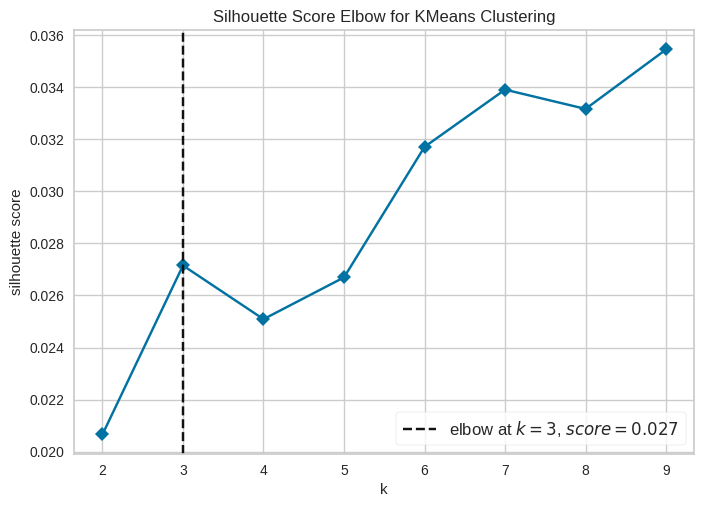

<Axes: title={'center': 'Silhouette Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='silhouette score'>

In [12]:

# 4. Menentukan k
model = KMeans(random_state=42)

visualizer = KElbowVisualizer(model,
                       k=(2,10),
                       metric='silhouette',
                       timings=False)

# Jalankan (fit) visualizer pada data
visualizer.fit(X)

# Tampilkan plot
visualizer.show()


In [15]:
# klasterisasi menggunakan k=3
k=3

model = KMeans(n_clusters=k, random_state=42)

# Latih (fit) model dengan data Anda (df)
labels = model.fit_predict(X)

df_clean['cluster'] = labels

df_clean.to_csv('df_clean_cluster.csv', index=False)

/tmp/ipykernel_4632/1735648202.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


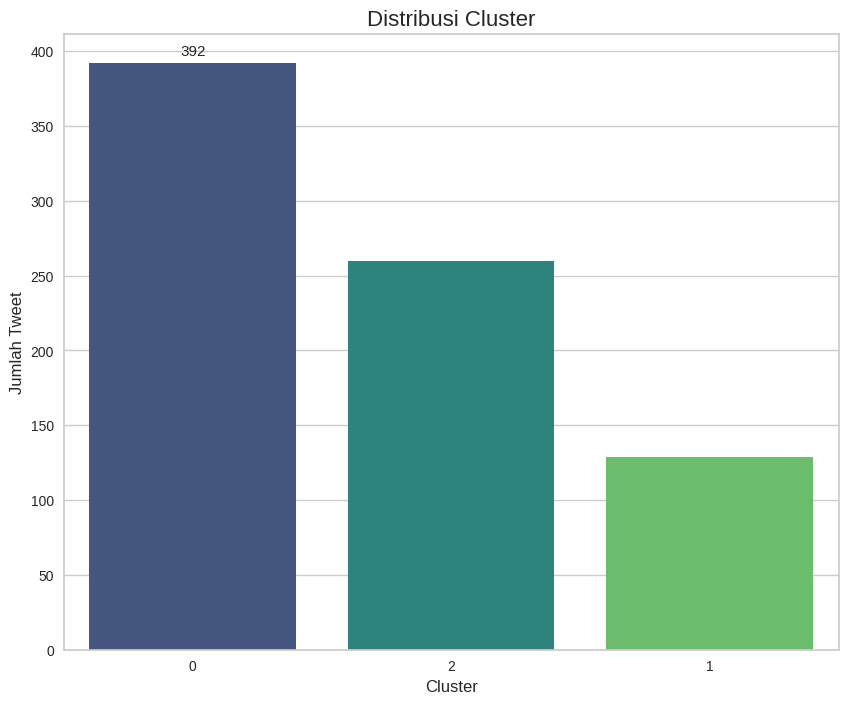

In [22]:
# distribusi labels

plt.figure(figsize=(10, 8))

# Buat plot dan simpan ke variabel 'ax'
ax = sns.countplot(
    x='cluster',
    data=df_clean,
    order=df_clean['cluster'].value_counts().index,
    palette='viridis'
)

# Tambahkan label total di atas setiap bar
ax.bar_label(ax.containers[0], padding=3, fontsize=11)

plt.title('Distribusi Cluster', fontsize=16)
plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Jumlah Tweet', fontsize=12)

plt.show()

     Principal Component 1  Principal Component 2  Cluster
0                -0.236986               0.142106        2
1                -0.001366              -0.201786        0
2                -0.179607               0.053399        2
3                -0.238874               0.142731        2
4                -0.287142               0.151581        2
..                     ...                    ...      ...
776               0.060734              -0.120347        0
777               0.300069               0.084124        1
778               0.074122              -0.136683        0
779               0.097879              -0.101268        0
780              -0.051013              -0.049671        0

[781 rows x 3 columns]


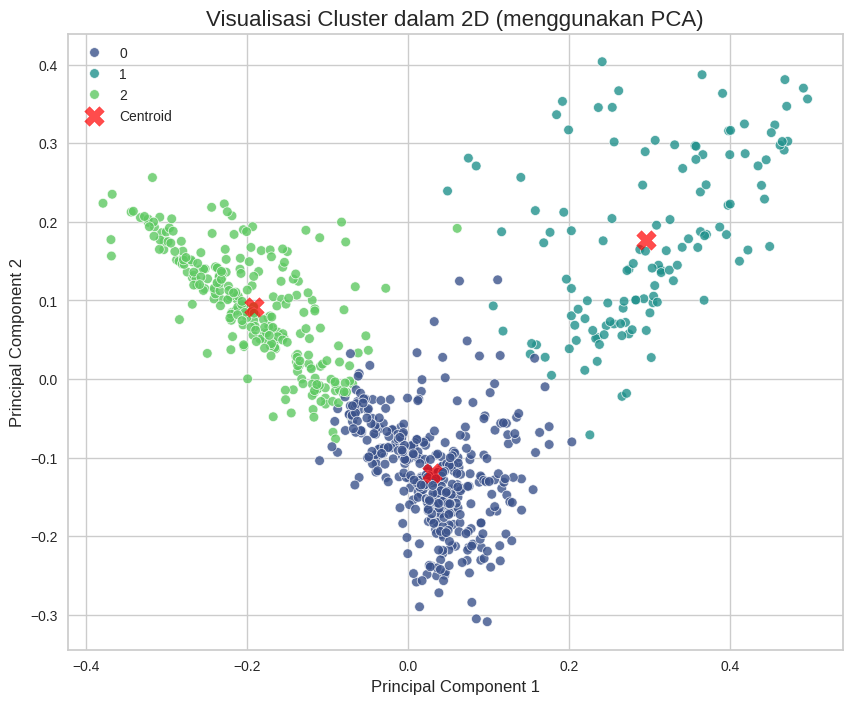

Variansi dijelaskan 2 komponen: 0.055


In [14]:
# PCA tidak menerima matriks sparse, jadi ubah X menjadi array padat
X_dense = X.toarray()

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_dense)

df_pca = pd.DataFrame(coords, columns=['Principal Component 1', 'Principal Component 2'])
df_pca['Cluster'] = labels
print(df_pca)

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='Principal Component 1',
    y='Principal Component 2',
    hue='Cluster',
    palette=sns.color_palette('viridis', n_colors=k),   # n_colors disamakan dengan k = 3
    data=df_pca,
    legend='full',
    alpha=0.8
)

# Centroid diproyeksikan dengan PCA yang sama
centers = pca.transform(model.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.7, marker='X', label='Centroid')

plt.title('Visualisasi Cluster dalam 2D (menggunakan PCA)', fontsize=16)
plt.xlabel('Principal Component 1', fontsize=12)
plt.ylabel('Principal Component 2', fontsize=12)
plt.legend()
plt.show()

print('Variansi dijelaskan 2 komponen:', pca.explained_variance_ratio_.sum().round(3))

In [23]:
# import model sentiment

feature_bow = pickle.load(open('/content/drive/MyDrive/Clustering Teks Twitter/feature-bow.p', 'rb'))
model_nn = pickle.load(open('/content/drive/MyDrive/Clustering Teks Twitter/model-nn.p', 'rb'))
model_nb = pickle.load(open('/content/drive/MyDrive/Clustering Teks Twitter/model-nb.p', 'rb'))

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator CountVectorizer from version 0.22.2.post1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LabelBinarizer from version 0.22.2.post1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator MLPClassifier from version 0.22.2.post1 when using version 1.6.1. This might lead

In [24]:
# Fungsi prediksi sentimen data teks twitter yang sudah di clean
def predict_sentiment(sent):
  text_feature = feature_bow.transform([sent])
  return model_nb.predict(text_feature)

df_clean['sentiment'] = df_clean.clean_text.apply(predict_sentiment)
negative_tweet = df_clean.loc[df_clean['sentiment'] == 'negative', 'full_text']

for i, teks in enumerate(negative_tweet.head(), 1):
    print(f'{i}. {teks}\n')

positive_tweet = df_clean.loc[df_clean['sentiment'] == 'positive', 'full_text']

for i, teks in enumerate(positive_tweet.head(), 1):
    print(f'{i}. {teks}\n')

# save csv
df_clean.to_csv('df_clean_sentiment.csv', index=False)

1. Sebanyak 18 siswa sekolah dasar di Kecamatan Purwareja Klampok, Kabupaten Banjarnegara, mengalami mual, pusing, muntah, dan sakit perut setelah menyantap Makanan Bergizi Gratis (MBG), Senin (28/9/2026).

#suaramerdeka #mbg #mual #muntah #siswasd #keluhanmbg #keracunanmbg https://t.co/9QRw2Lfjpu

2. "Semiskin-miskinnya orang tua, masih bisa kasih makan anak." Satu kalimat dari wali murid Turi, Sleman ini nusuk banget , dan sayangnya, dia ada benernya.

Puluhan pelajar dari 3 sekolah di Turi masuk puskesmas gara-gara pusing, mual, muntah, sakit perut abis makan menu MBG (7

3. Berdasarkan pantauan di lokasi aksi, para pelajar yang mengenakan seragam sekolah tampak membentangkan beberapa spanduk utama bertuliskan aspirasi mereka, di antaranya:

"KAMI BUTUH PENDIDIKAN GRATIS!!! BUKAN (MBG) - YALIMO TOLAK MAKANAN BERGIZI GRATIS!!!"

4. Ada satu kalimat yang keluar dari mulut presiden yang menurut netizen bisa jadi bumerang buat dirinya sendiri.

"Orang pintar yang mengkritik, saking pint

/tmp/ipykernel_4632/1642317329.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='sentiment', data=df_clean, order=df_clean['sentiment'].value_counts().index, palette='viridis')


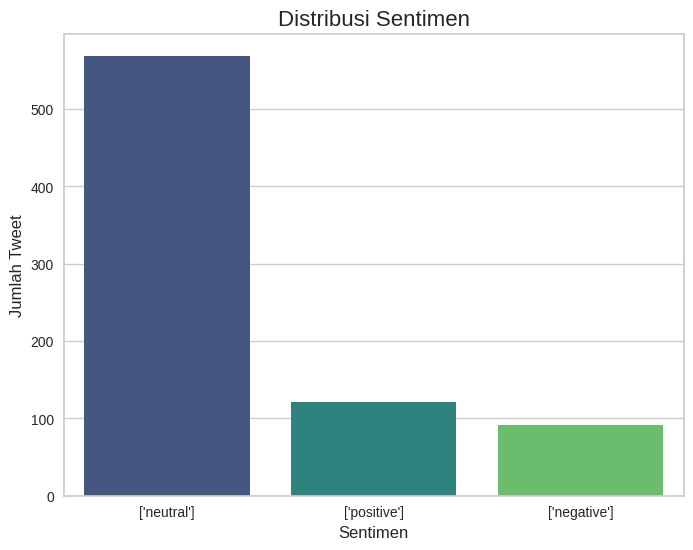

In [25]:
# tampilkan distribusi sentimen

plt.figure(figsize=(8, 6))
sns.countplot(x='sentiment', data=df_clean, order=df_clean['sentiment'].value_counts().index, palette='viridis')
plt.title('Distribusi Sentimen', fontsize=16)
plt.xlabel('Sentimen', fontsize=12)
plt.ylabel('Jumlah Tweet', fontsize=12)
plt.show()

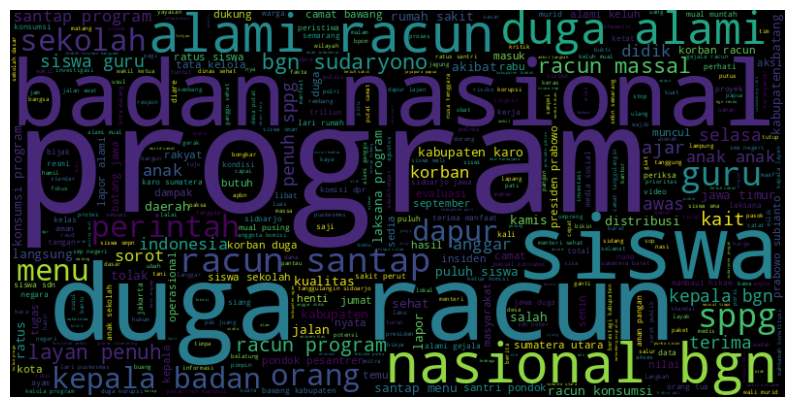

In [9]:
# World Cloud

#Gabungkan teks dari kolom 'clean_text'
data_text = ' '.join(df_clean['clean_text'].astype(str).tolist())
#Generate WordCloud
wc = WordCloud(stopwords=STOPWORDS, background_color='black', max_words=500, width=800, height=400).generate(data_text)
# Tampilkan WordCloud menggunakan matplotlib
plt.figure(figsize=(10, 10))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off') # Sembunyikan axis
plt.show()

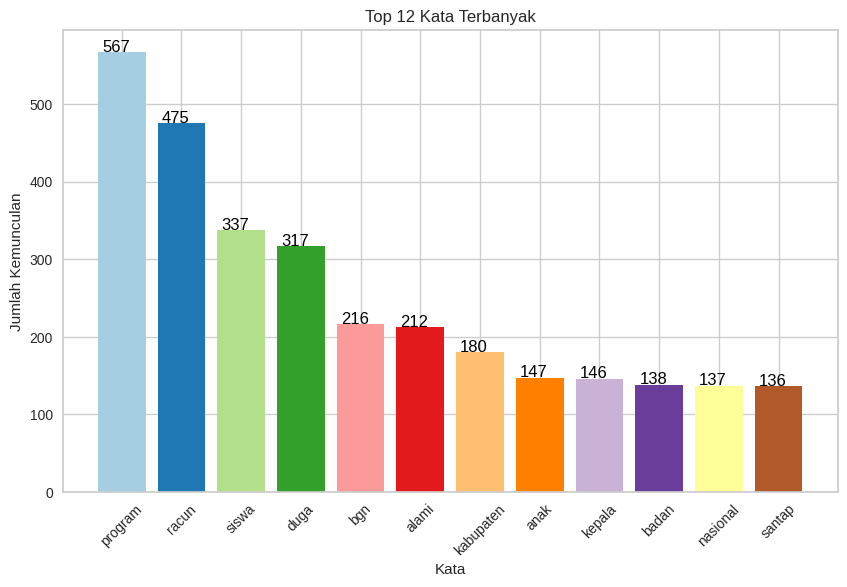

In [10]:
# kata yang sering muncul
text = ' '.join(df_clean['clean_text'].astype(str).tolist())
words = text.split()

word_counts = Counter(words)

top_words = word_counts.most_common(12)

words, counts = zip(*top_words)

colors = plt.cm.Paired(range(len(words)))

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(words, counts, color=colors)

ax.set_xlabel('Kata')
ax.set_ylabel('Jumlah Kemunculan')
ax.set_title('Top 12 Kata Terbanyak')
ax.set_xticks(range(len(words)))
ax.set_xticklabels(words, rotation=45)

for bar, num in zip(bars, counts):
  ax.text(bar.get_x() + bar.get_width() / 2 - 0.1, num + 1, str(num), fontsize=12, color='black', ha='center')

plt.show()

In [26]:
# membuat model prediksi sentimen dari data tweet ini
data_sentiment = pd.read_csv('df_clean_sentiment.csv')

X = data_sentiment['clean_text']
y = data_sentiment['sentiment']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer(min_df=5, max_df=0.8, ngram_range=(1, 2), max_features=5000)),
    ('model', LogisticRegression())
])

pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)

print(classification_report(y_test, y_pred))

joblib.dump(pipeline, 'model_sentiment_tweet.joblib')

              precision    recall  f1-score   support

['negative']       1.00      0.10      0.18        20
 ['neutral']       0.76      1.00      0.87       146
['positive']       1.00      0.10      0.18        30

    accuracy                           0.77       196
   macro avg       0.92      0.40      0.41       196
weighted avg       0.82      0.77      0.69       196



['model_sentiment_tweet.joblib']